In [1]:


# STEP 1: Install required library
!pip install -q ucimlrepo

# STEP 2: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Display settings
pd.set_option("display.max_columns", None)

print("MileageMind environment is ready!")

MileageMind environment is ready!


In [2]:

# Fetch the Auto MPG dataset
auto_mpg = fetch_ucirepo(id=9)

# Separate features and target
X = auto_mpg.data.features
y = auto_mpg.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

# Add car names if available
if auto_mpg.data.ids is not None:
    df = pd.concat([df, auto_mpg.data.ids], axis=1)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

# Display first 5 records
df.head()

Dataset downloaded successfully!
Dataset shape: (398, 9)


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg,car_name
0,307.0,8,130.0,3504,12.0,70,1,18.0,"chevrolet,chevelle,malibu"
1,350.0,8,165.0,3693,11.5,70,1,15.0,"buick,skylark,320"
2,318.0,8,150.0,3436,11.0,70,1,18.0,"plymouth,satellite"
3,304.0,8,150.0,3433,12.0,70,1,16.0,"amc,rebel,sst"
4,302.0,8,140.0,3449,10.5,70,1,17.0,"ford,torino"


In [3]:

# ==========================================
# MILEAGEMIND - FUEL EFFICIENCY PREDICTION
# ==========================================

!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib
import os

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("MileageMind environment is ready!")


MileageMind environment is ready!


In [4]:

# Download Auto MPG dataset from UCI
auto_mpg = fetch_ucirepo(id=9)

# Get input features and target
X = auto_mpg.data.features.copy()
y = auto_mpg.data.targets.copy()

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset downloaded successfully!
Dataset shape: (398, 8)


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
0,307.0,8,130.0,3504,12.0,70,1,18.0
1,350.0,8,165.0,3693,11.5,70,1,15.0
2,318.0,8,150.0,3436,11.0,70,1,18.0
3,304.0,8,150.0,3433,12.0,70,1,16.0
4,302.0,8,140.0,3449,10.5,70,1,17.0


In [5]:

# Dataset information
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nMissing Values:")
display(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
 7   mpg           398 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.0 KB

Dataset Shape:
(398, 8)

Column Names:
['displacement', 'cylinders', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'mpg']

Statistical Summary:


,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000



Missing Values:


,0
displacement,0
cylinders,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
mpg,0


In [6]:

# Make a copy for cleaning
df_clean = df.copy()

# Remove duplicate records
df_clean.drop_duplicates(inplace=True)

# Convert numeric columns to numeric format
numeric_columns = [
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
    "cylinders",
    "mpg"
]

for col in numeric_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

# Check missing values after conversion
print("Missing values before imputation:")
display(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)


Missing values before imputation:


,0
displacement,0
cylinders,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
mpg,0



Cleaned dataset shape: (398, 8)


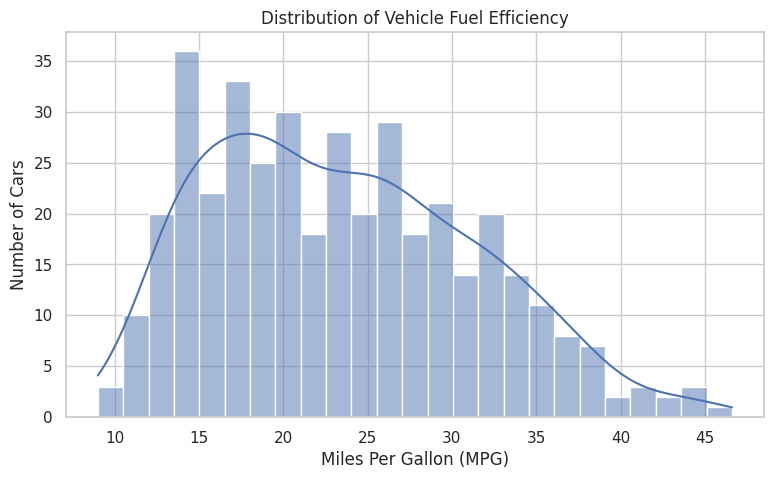

In [7]:

plt.figure(figsize=(9, 5))

sns.histplot(
    df_clean["mpg"].dropna(),
    bins=25,
    kde=True
)

plt.title("Distribution of Vehicle Fuel Efficiency")
plt.xlabel("Miles Per Gallon (MPG)")
plt.ylabel("Number of Cars")

plt.show()


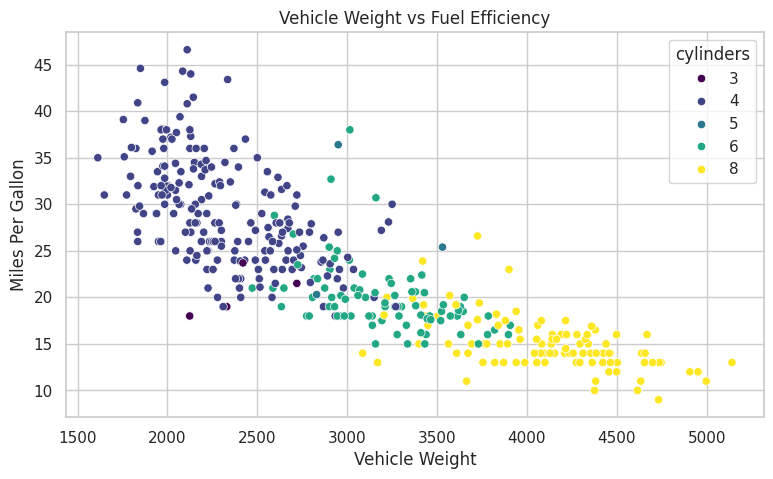

In [8]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x="weight",
    y="mpg",
    hue="cylinders",
    palette="viridis"
)

plt.title("Vehicle Weight vs Fuel Efficiency")
plt.xlabel("Vehicle Weight")
plt.ylabel("Miles Per Gallon")

plt.show()


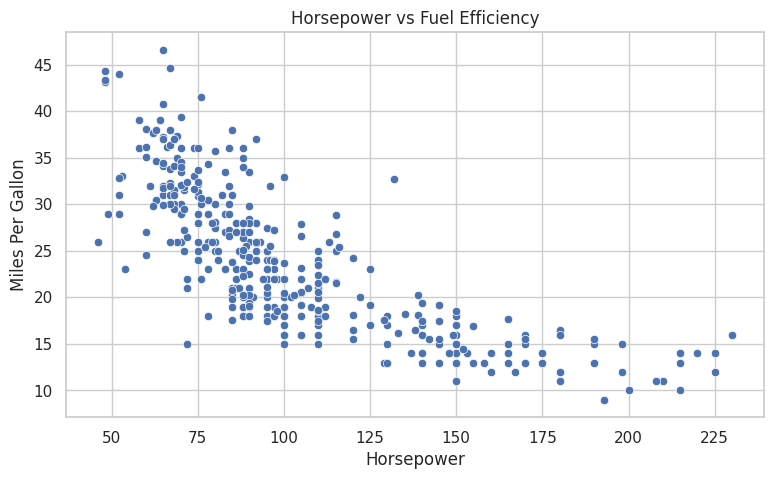

In [9]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df_clean,
    x="horsepower",
    y="mpg"
)

plt.title("Horsepower vs Fuel Efficiency")
plt.xlabel("Horsepower")
plt.ylabel("Miles Per Gallon")

plt.show()


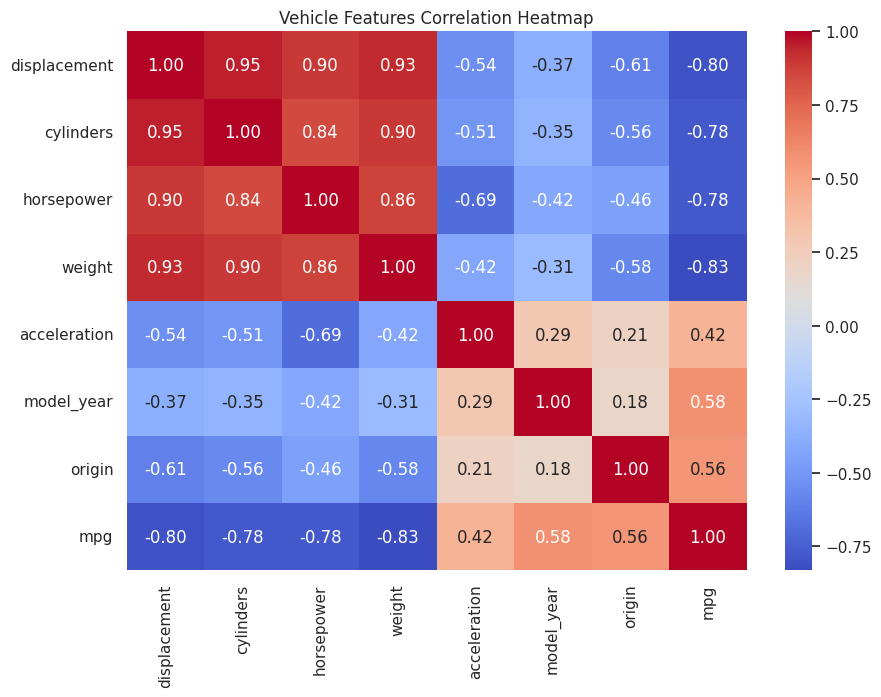

In [10]:

plt.figure(figsize=(10, 7))

correlation = df_clean.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Vehicle Features Correlation Heatmap")
plt.show()


In [11]:

# Separate input features and target
X = df_clean.drop(columns=["mpg"])
y = df_clean["mpg"]

# Remove rows where target MPG is missing
valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target variable: MPG")


Numerical features: ['displacement', 'cylinders', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin']
Categorical features: []
Target variable: MPG


In [12]:

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [13]:

# Treat discrete vehicle specifications as categories
# Origin, cylinders and model year are discrete variables

X = df_clean.loc[
    valid_rows, auto_mpg.data.features.columns
].copy()

categorical_columns = [
    "cylinders", "model_year", "origin"
]

for col in categorical_columns:
    X[col] = X[col].astype(str)

numeric_features = [
    col for col in X.select_dtypes(include=np.number).columns
]

categorical_features = [
    col for col in X.columns if col not in numeric_features
]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training and testing split completed!")


Training records: 318
Testing records: 80
Training and testing split completed!


In [14]:

# Define models
models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=10
    )
}

# Store trained models
trained_models = {}

# Train each model
for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll models have been trained!")


Baseline trained successfully!
Linear Regression trained successfully!
Random Forest trained successfully!

All models have been trained!


In [15]:

results = []

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
)

display(results_df.round(3))


,Model,MAE,RMSE,R2 Score
2,Random Forest,1.574,2.173,0.912
1,Linear Regression,2.256,2.863,0.848
0,Baseline,5.955,7.347,-0.004


In [16]:

results = []

predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
)

display(results_df.round(3))


,Model,MAE,RMSE,R2 Score
2,Random Forest,1.574,2.173,0.912
1,Linear Regression,2.256,2.863,0.848
0,Baseline,5.955,7.347,-0.004


,Feature,Importance
0,num__displacement,0.404461
3,num__weight,0.175296
1,num__cylinders,0.142471
2,num__horsepower,0.126590
5,num__model_year,0.118676
4,num__acceleration,0.026855
6,num__origin,0.005651


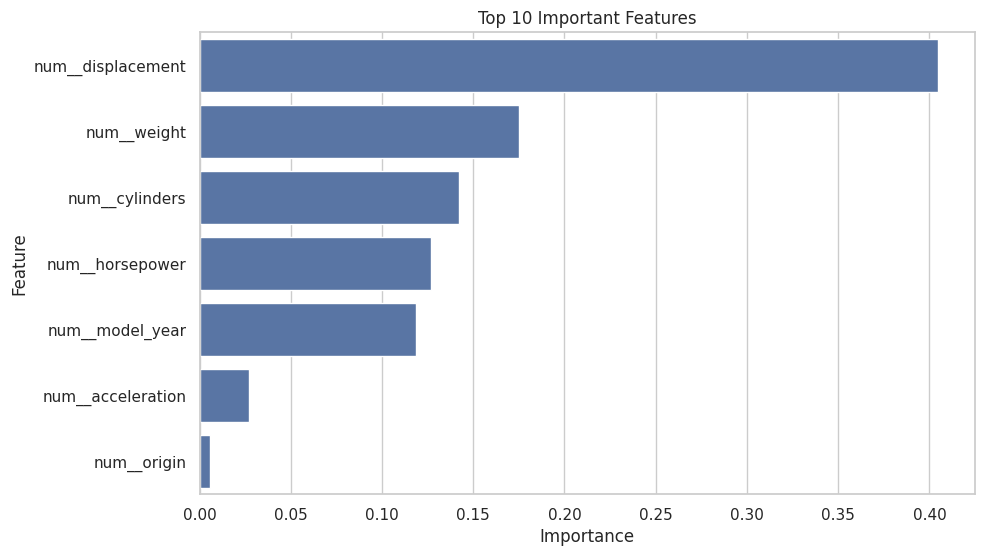

In [17]:

# Extract trained Random Forest
rf_pipeline = trained_models["Random Forest"]

# Get transformed feature names
feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get feature importance
importance = (
    rf_pipeline
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.show()

In [18]:

# Rebuild preprocessing using the corrected feature types

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Updated preprocessing pipeline ready!")
print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Updated preprocessing pipeline ready!
Numerical: ['displacement', 'horsepower', 'weight', 'acceleration']
Categorical: ['cylinders', 'model_year', 'origin']


In [19]:

# Choose the best non-baseline model using test RMSE
candidate_results = results_df[
    results_df["Model"] != "Baseline"
]

best_model_name = candidate_results.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

# Create a sample vehicle
new_car = pd.DataFrame([{
    "cylinders": "4",
    "displacement": 120,
    "horsepower": 90,
    "weight": 2500,
    "acceleration": 15,
    "model_year": "80",
    "origin": "3"
}])

# Predict fuel efficiency
predicted_mpg = best_model.predict(new_car)[0]

# Convert US MPG to approximate km/l
predicted_kmpl = predicted_mpg * 0.425144

print("\n========== MILEAGEMIND ==========")
print("Predicted Fuel Efficiency:")
print(round(predicted_mpg, 2), "MPG")
print(round(predicted_kmpl, 2), "KM/L")
print("================================")

Selected model: Random Forest

========== MILEAGEMIND ==========
Predicted Fuel Efficiency:
34.35 MPG
14.6 KM/L


In [20]:

# Create output directories
os.makedirs("MileageMind/outputs/figures", exist_ok=True)

# Save trained model
joblib.dump(
    best_model,
    "MileageMind/mileagemind_model.pkl"
)

# Save model comparison
results_df.to_csv(
    "MileageMind/outputs/model_comparison.csv",
    index=False
)

# Save test predictions
prediction_output = pd.DataFrame({
    "Actual_MPG": y_test.values,
    "Predicted_MPG": best_model.predict(X_test)
})

prediction_output.to_csv(
    "MileageMind/outputs/predictions.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    "MileageMind/outputs/feature_importance.csv",
    index=False
)

print("Project outputs saved successfully!")

Project outputs saved successfully!


In [21]:

# Create a requirements file
requirements = """
pandas
numpy
matplotlib
seaborn
scikit-learn
ucimlrepo
joblib
"""

with open(
    "MileageMind/requirements.txt", "w"
) as file:
    file.write(requirements.strip() + "\n")

# Zip project outputs
import shutil

shutil.make_archive(
    "MileageMind",
    "zip",
    "MileageMind"
)

print("MileageMind.zip created!")

MileageMind.zip created!


In [22]:

from google.colab import files

files.download("MileageMind.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>